In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
!nvidia-smi
import torch
print(torch.__version__, "| cuda:", torch.cuda.is_available())
!find /kaggle/input -maxdepth 3 -type d | head -20

Tue Nov 24 14:58:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
%cd /kaggle/working
!git clone https://github.com/TencentYoutuResearch/CrowdCounting-P2PNet.git
%cd CrowdCounting-P2PNet
!sed -i "s#torch.load(model_paths\[arch\])#torch.hub.load_state_dict_from_url('https://download.pytorch.org/models/vgg16_bn-6c64b313.pth' if arch == 'vgg16_bn' else 'https://download.pytorch.org/models/vgg16-397923af.pth', map_location='cpu')#" models/vgg_.py
!pip install -q tensorboardX easydict
!mkdir -p logs /kaggle/working/smoke_ckpt

/kaggle/working
Cloning into 'CrowdCounting-P2PNet'...
remote: Enumerating objects: 38, done.
remote: Counting objects: 100% (20/20), done.
remote: Compressing objects: 100% (18/18), done.
remote: Total 38 (delta 3), reused 2 (delta 2), pack-reused 18 (from 1)
Receiving objects: 100% (38/38), 90.70 MiB | 40.59 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/kaggle/working/CrowdCounting-P2PNet


In [3]:
%%writefile /kaggle/working/prepare_shha_for_p2pnet.py
import os, sys, glob, shutil
from scipy.io import loadmat

def load_points(mat_path):
    return loadmat(mat_path)["image_info"][0, 0][0, 0][0]

def convert_split(src_root, out_root, split):
    img_dir = os.path.join(src_root, split, "images")
    gt_dir = os.path.join(src_root, split, "ground_truth")
    out_img = os.path.join(out_root, split, "images")
    out_gt = os.path.join(out_root, split, "ground_truth")
    os.makedirs(out_img, exist_ok=True); os.makedirs(out_gt, exist_ok=True)
    lines = []
    for p in sorted(glob.glob(os.path.join(img_dir, "*.jpg"))):
        base = os.path.splitext(os.path.basename(p))[0]
        pts = load_points(os.path.join(gt_dir, f"GT_{base}.mat"))
        shutil.copy(p, os.path.join(out_img, base + ".jpg"))
        with open(os.path.join(out_gt, base + ".txt"), "w") as f:
            for x, y in pts:
                f.write(f"{float(x)} {float(y)}\n")
        lines.append(f"{split}/images/{base}.jpg {split}/ground_truth/{base}.txt")
    return lines

src, out = sys.argv[1], sys.argv[2]
for split, name in [("train_data", "shanghai_tech_part_a_train.list"),
                    ("test_data", "shanghai_tech_part_a_test.list")]:
    lines = convert_split(src, out, split)
    open(os.path.join(out, name), "w").write("\n".join(lines) + "\n")
    print(split, len(lines), "images")

Writing /kaggle/working/prepare_shha_for_p2pnet.py


In [9]:
import glob, os
cands = glob.glob('/kaggle/input/**/train_data', recursive=True)
print(cands)
SRC = os.path.dirname(cands[0])
print("SRC =", SRC)
print(os.listdir(SRC))

['/kaggle/input/datasets/amritask/p2pparta/part_A_final/train_data']
SRC = /kaggle/input/datasets/amritask/p2pparta/part_A_final
['test_data', 'train_data']


In [11]:
SRC = "/kaggle/input/datasets/amritask/p2pparta/part_A_final"
!ls "{SRC}/train_data"
!ls "{SRC}/train_data/images" | head -3
!ls "{SRC}/train_data/ground_truth" | head -3

ground_truth  images
IMG_100.jpg
IMG_101.jpg
IMG_102.jpg
GT_IMG_100.mat
GT_IMG_101.mat
GT_IMG_102.mat


In [12]:
SRC = "/kaggle/input/datasets/amritask/p2pparta/part_A_final"
!python /kaggle/working/prepare_shha_for_p2pnet.py "{SRC}" /kaggle/working/p2p_data

train_data 300 images
test_data 182 images


In [13]:
!ls /kaggle/working/p2p_data
!head -2 /kaggle/working/p2p_data/shanghai_tech_part_a_train.list

shanghai_tech_part_a_test.list	 test_data
shanghai_tech_part_a_train.list  train_data
train_data/images/IMG_1.jpg train_data/ground_truth/IMG_1.txt
train_data/images/IMG_10.jpg train_data/ground_truth/IMG_10.txt


In [14]:
import os, torch
print("cuda available:", torch.cuda.is_available())
print("repo cloned:", os.path.exists("/kaggle/working/CrowdCounting-P2PNet/models/vgg_.py"))
!grep -n "hub.load_state_dict_from_url" /kaggle/working/CrowdCounting-P2PNet/models/vgg_.py
!ls -d /kaggle/working/CrowdCounting-P2PNet/logs /kaggle/working/smoke_ckpt

cuda available: True
repo cloned: True
106:        state_dict = torch.hub.load_state_dict_from_url('https://download.pytorch.org/models/vgg16_bn-6c64b313.pth' if arch == 'vgg16_bn' else 'https://download.pytorch.org/models/vgg16-397923af.pth', map_location='cpu')
/kaggle/working/CrowdCounting-P2PNet/logs  /kaggle/working/smoke_ckpt


In [15]:
import pathlib

root = pathlib.Path("/kaggle/working/CrowdCounting-P2PNet")

# Patch 1: util/misc.py
p = root / "util/misc.py"
s = p.read_text()

# Replace torchvision version condition if present
s = s.replace(
    "if float(torchvision.__version__[:3]) < 0.7:",
    "if False:"
)

# Replace torchvision interpolate with PyTorch interpolate
s = s.replace(
    "torchvision.ops.misc.interpolate(",
    "torch.nn.functional.interpolate("
)

p.write_text(s)
print("Patched util/misc.py")


# Patch 2: SHHA.py
p = root / "crowd_datasets/SHHA/SHHA.py"
s = p.read_text()

old = "torch.nn.functional.upsample_bilinear(img.unsqueeze(0), scale_factor=scale)"

new = """torch.nn.functional.interpolate(
    img.unsqueeze(0),
    scale_factor=scale,
    mode='bilinear',
    align_corners=True
)"""

if old in s:
    s = s.replace(old, new)
    print("Replaced upsample_bilinear")
else:
    print("upsample_bilinear not found; checking existing code")

p.write_text(s)
print("Patched SHHA.py")

Patched util/misc.py
Replaced upsample_bilinear
Patched SHHA.py


In [16]:
import pathlib

root = pathlib.Path("/kaggle/working/CrowdCounting-P2PNet")

p = root / "crowd_datasets/SHHA/SHHA.py"
s = p.read_text()

# Check interpolation-related lines
print("Current interpolation code:")

for i, line in enumerate(s.splitlines(), 1):
    if "upsample" in line or "interpolate" in line:
        print(f"{i}: {line.strip()}")

# Replace deprecated function name if present
if "upsample_bilinear" in s:
    s = s.replace(
        "torch.nn.functional.upsample_bilinear(",
        "torch.nn.functional.interpolate("
    )

    # Add required interpolation arguments only
    p.write_text(s)
    print("\nDeprecated function replaced.")
else:
    print("\nNo deprecated upsample_bilinear found.")

Current interpolation code:
65: img = torch.nn.functional.interpolate(

No deprecated upsample_bilinear found.


In [17]:

%cd /kaggle/working/CrowdCounting-P2PNet

!python train.py \
  --data_root /kaggle/working/p2p_data \
  --dataset_file SHHA \
  --epochs 6 \
  --lr_drop 3500 \
  --lr 0.0001 \
  --lr_backbone 0.00001 \
  --batch_size 8 \
  --eval_freq 5 \
  --num_workers 4 \
  --gpu_id 0 \
  --output_dir ./logs \
  --tensorboard_dir ./logs \
  --checkpoints_dir /kaggle/working/smoke_ckpt


/kaggle/working/CrowdCounting-P2PNet
Namespace(lr=0.0001, lr_backbone=1e-05, batch_size=8, weight_decay=0.0001, epochs=6, lr_drop=3500, clip_max_norm=0.1, frozen_weights=None, backbone='vgg16_bn', set_cost_class=1, set_cost_point=0.05, point_loss_coef=0.0002, eos_coef=0.5, row=2, line=2, dataset_file='SHHA', data_root='/kaggle/working/p2p_data', output_dir='./logs', checkpoints_dir='/kaggle/working/smoke_ckpt', tensorboard_dir='./logs', seed=42, resume='', start_epoch=0, eval=False, num_workers=4, eval_freq=5, gpu_id=0)
Downloading: "https://download.pytorch.org/models/vgg16_bn-6c64b313.pth" to /root/.cache/torch/hub/checkpoints/vgg16_bn-6c64b313.pth
100%|█████████████████████████████████████████| 528M/528M [00:01<00:00, 359MB/s]
number of params: 21579344
Start training
Averaged stats: lr: 0.000100  loss: 0.1860 (0.3162)  loss_ce: 0.1860 (0.3162)  loss_ce_unscaled: 0.1860 (0.3162)  loss_point_unscaled: 4.8608 (4.3753)
[ep 0][lr 0.0001000][19.75s]
Averaged stats: lr: 0.000100  loss: 0.

In [18]:
from pathlib import Path

ckpt_dir = Path("/kaggle/working/smoke_ckpt")

print("Checkpoint directory exists:", ckpt_dir.exists())

for file in ckpt_dir.iterdir():
    print(file.name, round(file.stat().st_size / (1024 * 1024), 2), "MB")

Checkpoint directory exists: True
latest.pth 82.39 MB
best_mae.pth 82.39 MB


In [19]:

import torch
from pathlib import Path

ckpt_dir = Path("/kaggle/working/smoke_ckpt")

for filename in ["best_mae.pth", "latest.pth"]:
    path = ckpt_dir / filename

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    print(f"\n{filename}")
    print("Checkpoint loaded successfully!")

    if isinstance(checkpoint, dict):
        print("Available keys:", checkpoint.keys())


best_mae.pth
Checkpoint loaded successfully!
Available keys: dict_keys(['model'])

latest.pth
Checkpoint loaded successfully!
Available keys: dict_keys(['model'])


In [20]:

from pathlib import Path

root = Path("/kaggle/working/p2p_data")

def show_tree(path, depth=2, level=0):
    if level > depth:
        return

    for item in sorted(path.iterdir()):
        print("  " * level + item.name)

        if item.is_dir() and level < depth:
            show_tree(item, depth, level + 1)

show_tree(root)


shanghai_tech_part_a_test.list
shanghai_tech_part_a_train.list
test_data
  ground_truth
    IMG_1.txt
    IMG_10.txt
    IMG_100.txt
    IMG_101.txt
    IMG_102.txt
    IMG_103.txt
    IMG_104.txt
    IMG_105.txt
    IMG_106.txt
    IMG_107.txt
    IMG_108.txt
    IMG_109.txt
    IMG_11.txt
    IMG_110.txt
    IMG_111.txt
    IMG_112.txt
    IMG_113.txt
    IMG_114.txt
    IMG_115.txt
    IMG_116.txt
    IMG_117.txt
    IMG_118.txt
    IMG_119.txt
    IMG_12.txt
    IMG_120.txt
    IMG_121.txt
    IMG_122.txt
    IMG_123.txt
    IMG_124.txt
    IMG_125.txt
    IMG_126.txt
    IMG_127.txt
    IMG_128.txt
    IMG_129.txt
    IMG_13.txt
    IMG_130.txt
    IMG_131.txt
    IMG_132.txt
    IMG_133.txt
    IMG_134.txt
    IMG_135.txt
    IMG_136.txt
    IMG_137.txt
    IMG_138.txt
    IMG_139.txt
    IMG_14.txt
    IMG_140.txt
    IMG_141.txt
    IMG_142.txt
    IMG_143.txt
    IMG_144.txt
    IMG_145.txt
    IMG_146.txt
    IMG_147.txt
    IMG_148.txt
    IMG_149.txt
    IMG_15.txt
    IMG_

In [21]:

from pathlib import Path

root = Path("/kaggle/working/p2p_data")

for split in ["train_data", "test_data"]:
    images = root / split / "images"
    gt = root / split / "ground_truth"

    image_files = list(images.glob("*.jpg"))
    gt_files = list(gt.glob("*.txt"))

    print(f"\n{split}")
    print("Images:", len(image_files))
    print("Ground truth:", len(gt_files))

    image_names = {p.stem for p in image_files}
    gt_names = {p.stem for p in gt_files}

    print("Missing annotations:", len(image_names - gt_names))
    print("Missing images:", len(gt_names - image_names))

# Check list files
for filename in [
    "shanghai_tech_part_a_train.list",
    "shanghai_tech_part_a_test.list"
]:
    p = root / filename
    print(f"\n{filename} exists:", p.exists())

    if p.exists():
        print("First 5 entries:")
        print("\n".join(p.read_text().splitlines()[:5]))



train_data
Images: 300
Ground truth: 300
Missing annotations: 0
Missing images: 0

test_data
Images: 182
Ground truth: 182
Missing annotations: 0
Missing images: 0

shanghai_tech_part_a_train.list exists: True
First 5 entries:
train_data/images/IMG_1.jpg train_data/ground_truth/IMG_1.txt
train_data/images/IMG_10.jpg train_data/ground_truth/IMG_10.txt
train_data/images/IMG_100.jpg train_data/ground_truth/IMG_100.txt
train_data/images/IMG_101.jpg train_data/ground_truth/IMG_101.txt
train_data/images/IMG_102.jpg train_data/ground_truth/IMG_102.txt

shanghai_tech_part_a_test.list exists: True
First 5 entries:
test_data/images/IMG_1.jpg test_data/ground_truth/IMG_1.txt
test_data/images/IMG_10.jpg test_data/ground_truth/IMG_10.txt
test_data/images/IMG_100.jpg test_data/ground_truth/IMG_100.txt
test_data/images/IMG_101.jpg test_data/ground_truth/IMG_101.txt
test_data/images/IMG_102.jpg test_data/ground_truth/IMG_102.txt


In [22]:
p = Path("/kaggle/working/CrowdCounting-P2PNet/crowd_datasets/SHHA/SHHA.py")

for i, line in enumerate(p.read_text().splitlines(), 1):
    if any(x in line.lower() for x in ["data_root", "train_data", "test_data", ".list", "ground_truth"]):
        print(f"{i}: {line.strip()}")

12: def __init__(self, data_root, transform=None, train=False, patch=False, flip=False):
13: self.root_path = data_root
14: self.train_lists = "shanghai_tech_part_a_train.list"
15: self.eval_list = "shanghai_tech_part_a_test.list"


In [23]:
from pathlib import Path

root = Path("/kaggle/working/p2p_data")

for split in ["train_data", "test_data"]:
    images = root / split / "images"
    gt = root / split / "ground_truth"

    image_files = list(images.glob("*.jpg"))
    gt_files = list(gt.glob("*.txt"))

    print(f"\n{split}")
    print("Images:", len(image_files))
    print("Ground truth:", len(gt_files))

    image_names = {p.stem for p in image_files}
    gt_names = {p.stem for p in gt_files}

    print("Missing annotations:", len(image_names - gt_names))
    print("Missing images:", len(gt_names - image_names))

# Check list files
for filename in [
    "shanghai_tech_part_a_train.list",
    "shanghai_tech_part_a_test.list"
]:
    p = root / filename
    print(f"\n{filename} exists:", p.exists())

    if p.exists():
        print("First 5 entries:")
        print("\n".join(p.read_text().splitlines()[:5]))



train_data
Images: 300
Ground truth: 300
Missing annotations: 0
Missing images: 0

test_data
Images: 182
Ground truth: 182
Missing annotations: 0
Missing images: 0

shanghai_tech_part_a_train.list exists: True
First 5 entries:
train_data/images/IMG_1.jpg train_data/ground_truth/IMG_1.txt
train_data/images/IMG_10.jpg train_data/ground_truth/IMG_10.txt
train_data/images/IMG_100.jpg train_data/ground_truth/IMG_100.txt
train_data/images/IMG_101.jpg train_data/ground_truth/IMG_101.txt
train_data/images/IMG_102.jpg train_data/ground_truth/IMG_102.txt

shanghai_tech_part_a_test.list exists: True
First 5 entries:
test_data/images/IMG_1.jpg test_data/ground_truth/IMG_1.txt
test_data/images/IMG_10.jpg test_data/ground_truth/IMG_10.txt
test_data/images/IMG_100.jpg test_data/ground_truth/IMG_100.txt
test_data/images/IMG_101.jpg test_data/ground_truth/IMG_101.txt
test_data/images/IMG_102.jpg test_data/ground_truth/IMG_102.txt


In [24]:
from pathlib import Path

# Create required directories
Path("./logs_full").mkdir(parents=True, exist_ok=True)
Path("/kaggle/working/p2p_full_ckpt").mkdir(
    parents=True, exist_ok=True
)

print("Directories created successfully!")


Directories created successfully!


In [25]:
%cd /kaggle/working/CrowdCounting-P2PNet

!python train.py \
  --data_root /kaggle/working/p2p_data \
  --dataset_file SHHA \
  --epochs 100 \
  --lr_drop 3500 \
  --lr 0.0001 \
  --lr_backbone 0.00001 \
  --batch_size 8 \
  --eval_freq 10 \
  --num_workers 4 \
  --gpu_id 0 \
  --output_dir ./logs_full \
  --tensorboard_dir ./logs_full \
  --checkpoints_dir /kaggle/working/p2p_full_ckpt


/kaggle/working/CrowdCounting-P2PNet
Namespace(lr=0.0001, lr_backbone=1e-05, batch_size=8, weight_decay=0.0001, epochs=100, lr_drop=3500, clip_max_norm=0.1, frozen_weights=None, backbone='vgg16_bn', set_cost_class=1, set_cost_point=0.05, point_loss_coef=0.0002, eos_coef=0.5, row=2, line=2, dataset_file='SHHA', data_root='/kaggle/working/p2p_data', output_dir='./logs_full', checkpoints_dir='/kaggle/working/p2p_full_ckpt', tensorboard_dir='./logs_full', seed=42, resume='', start_epoch=0, eval=False, num_workers=4, eval_freq=10, gpu_id=0)
number of params: 21579344
Start training
Averaged stats: lr: 0.000100  loss: 0.1859 (0.3162)  loss_ce: 0.1859 (0.3162)  loss_ce_unscaled: 0.1859 (0.3162)  loss_point_unscaled: 4.8608 (4.3754)
[ep 0][lr 0.0001000][14.04s]
Averaged stats: lr: 0.000100  loss: 0.1252 (0.1542)  loss_ce: 0.1252 (0.1542)  loss_ce_unscaled: 0.1252 (0.1542)  loss_point_unscaled: 5.7837 (6.7362)
[ep 1][lr 0.0001000][13.26s]
Averaged stats: lr: 0.000100  loss: 0.1389 (0.1477)  los

In [26]:

from pathlib import Path
import torch

ckpt_dir = Path("/kaggle/working/p2p_full_ckpt")

print("Checkpoint files:")

for file in ckpt_dir.glob("*.pth"):
    print(file.name, round(file.stat().st_size / (1024 * 1024), 2), "MB")

best_path = ckpt_dir / "best_mae.pth"

if best_path.exists():
    checkpoint = torch.load(
        best_path,
        map_location="cpu",
        weights_only=False
    )

    print("\nBest checkpoint loaded!")
    print("Keys:", checkpoint.keys())
    print("Model parameters:", len(checkpoint["model"]))
else:
    print("best_mae.pth not found!")

Checkpoint files:
latest.pth 82.39 MB
best_mae.pth 82.39 MB

Best checkpoint loaded!
Keys: dict_keys(['model'])
Model parameters: 123


/kaggle/working/CrowdCounting-P2PNet
Using device: cuda
Best checkpoint loaded successfully!
Test images: 182

========== FINAL TEST RESULTS ==========
Test Images : 182
MAE         : 62.8516
RMSE        : 99.0000

Total visualization images saved: 364
Saved at: /kaggle/working/p2p_full_visualizations
100_gt_391_pred_405_gt.jpg


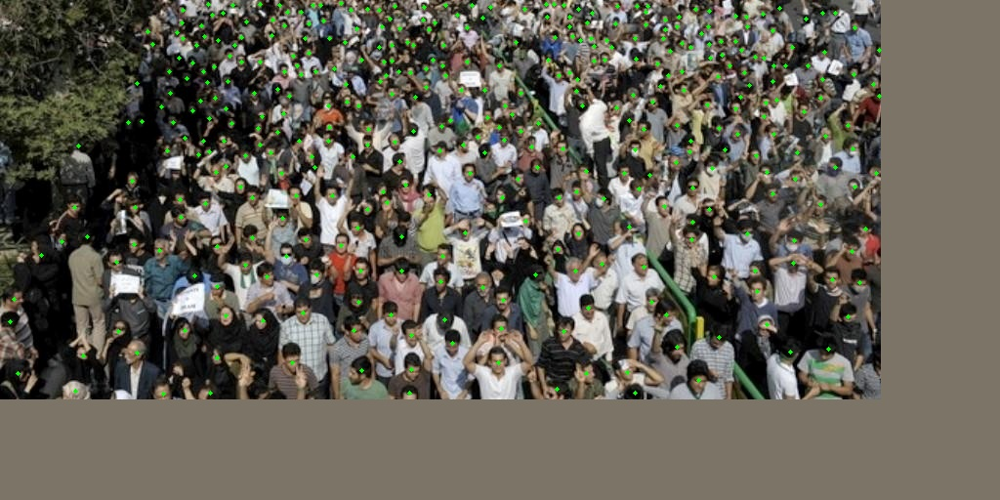

100_gt_391_pred_405_pred.jpg


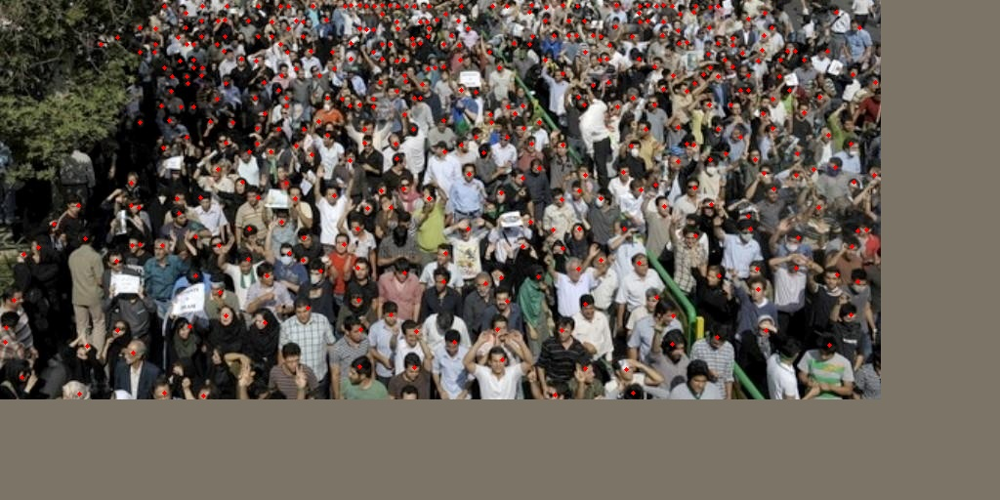

101_gt_211_pred_176_gt.jpg


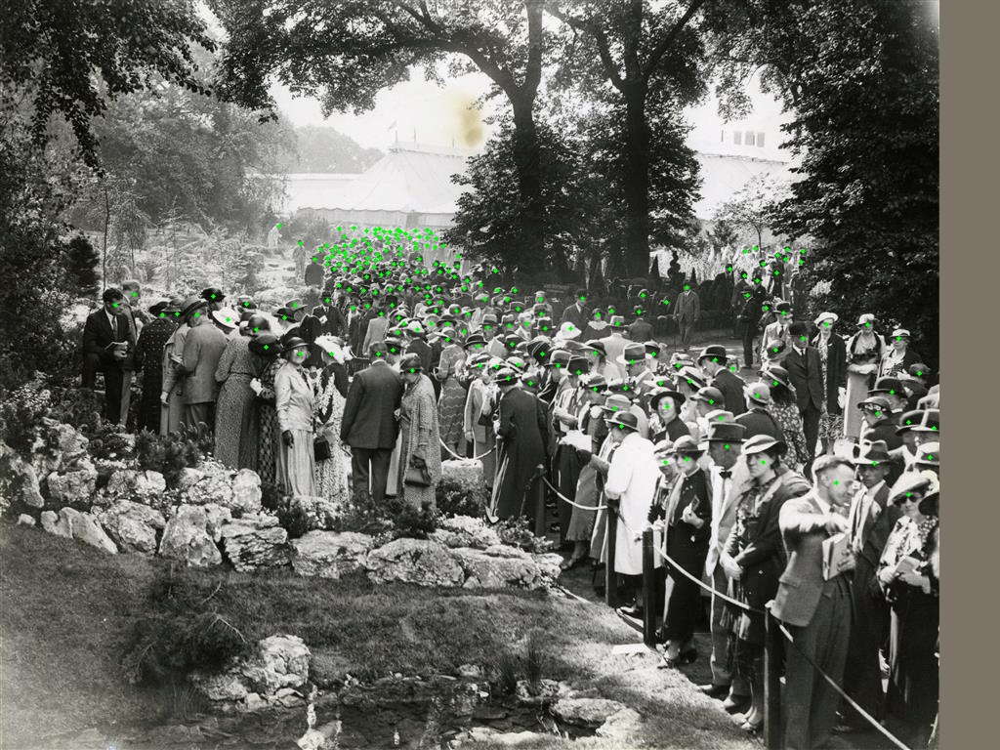

101_gt_211_pred_176_pred.jpg


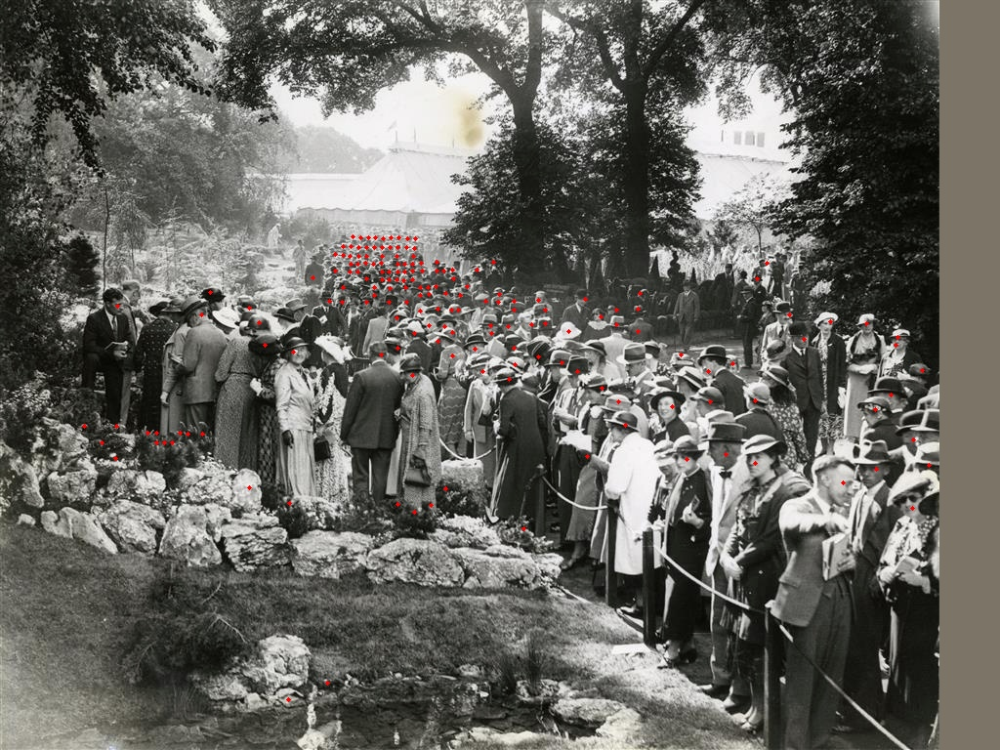

102_gt_223_pred_217_gt.jpg


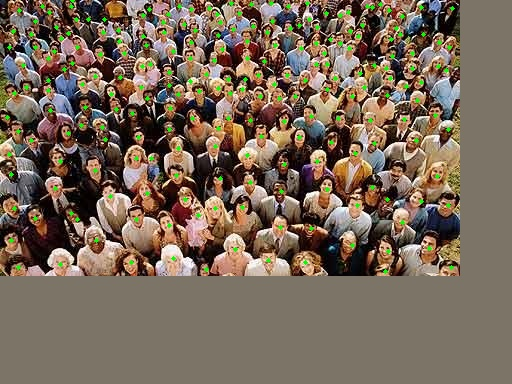

102_gt_223_pred_217_pred.jpg


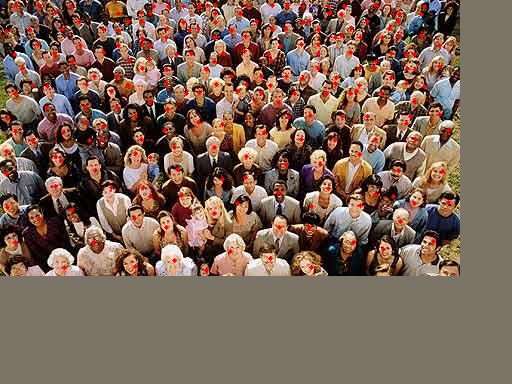

103_gt_431_pred_512_gt.jpg


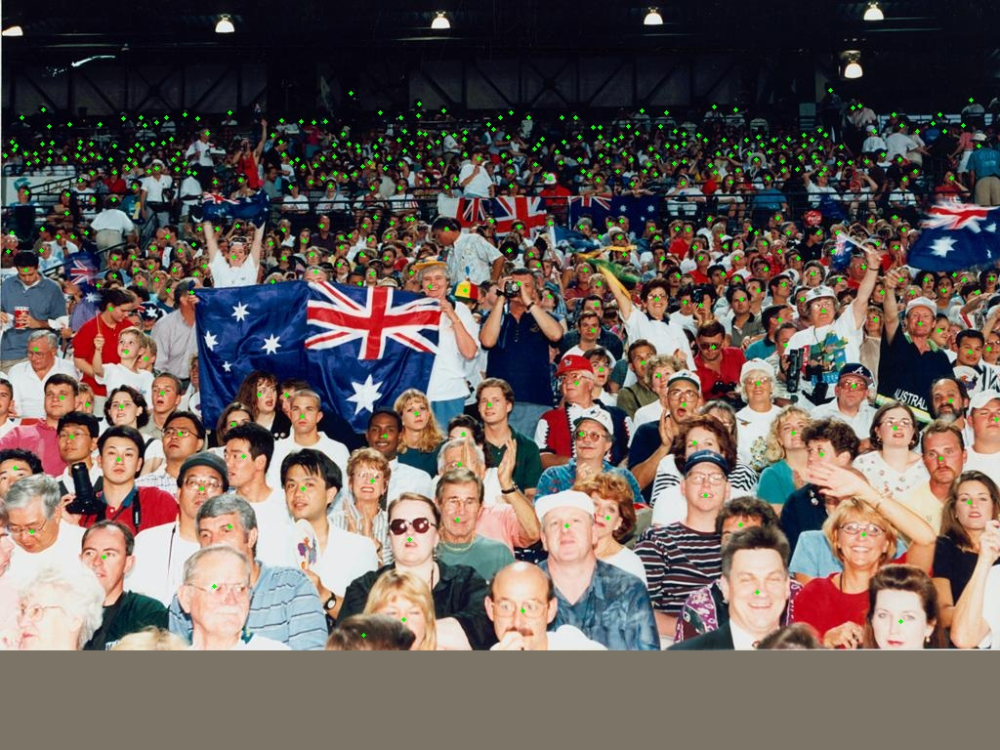

103_gt_431_pred_512_pred.jpg


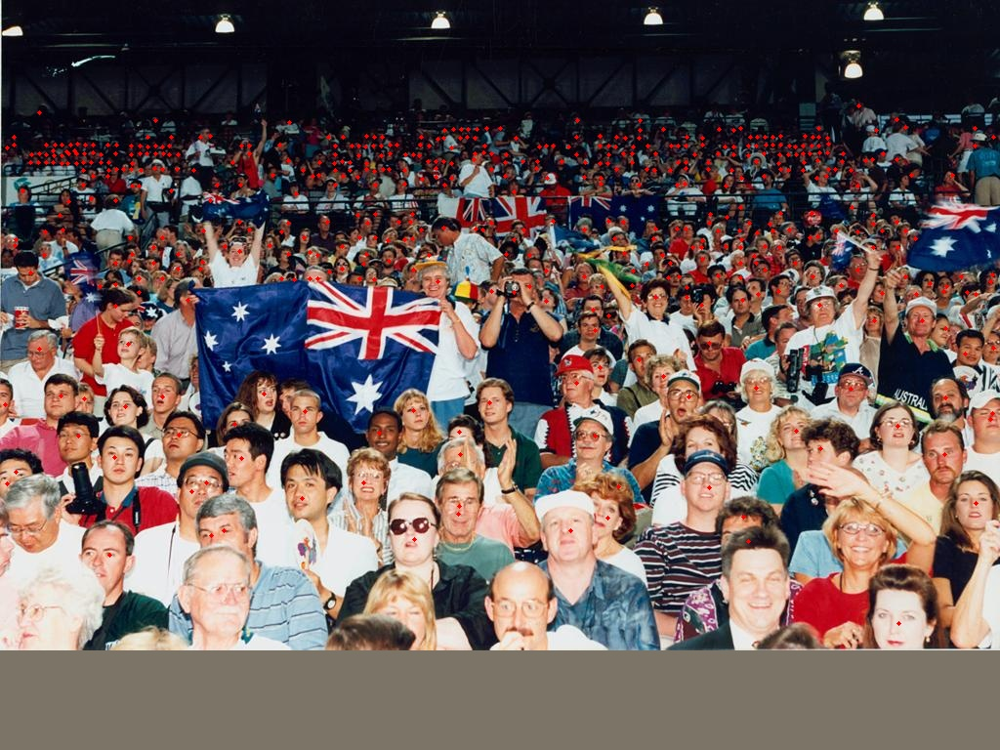

In [28]:

%cd /kaggle/working/CrowdCounting-P2PNet

import torch
import argparse
from pathlib import Path
from torch.utils.data import DataLoader
from IPython.display import display
from PIL import Image as PILImage

from models import build_model
from crowd_datasets.SHHA.loading_data import loading_data
from engine import evaluate_crowd_no_overlap
import util.misc as utils

# 1. Paths
DATA_ROOT = "/kaggle/working/p2p_data"
CHECKPOINT = "/kaggle/working/p2p_full_ckpt/best_mae.pth"
VIS_DIR = "/kaggle/working/p2p_full_visualizations"

Path(VIS_DIR).mkdir(parents=True, exist_ok=True)

assert Path(CHECKPOINT).exists(), "Best checkpoint not found!"
assert Path(DATA_ROOT).exists(), "Dataset directory not found!"

# 2. Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 3. Model configuration
args = argparse.Namespace(
    backbone="vgg16_bn",
    row=2,
    line=2
)

model = build_model(args)
model.to(device)

# 4. Load trained checkpoint
try:
    checkpoint = torch.load(
        CHECKPOINT,
        map_location="cpu",
        weights_only=False
    )
except TypeError:
    checkpoint = torch.load(CHECKPOINT, map_location="cpu")

model.load_state_dict(checkpoint["model"])
model.eval()

print("Best checkpoint loaded successfully!")

# 5. Load test dataset
train_set, test_set = loading_data(DATA_ROOT)

print("Test images:", len(test_set))

test_loader = DataLoader(
    test_set,
    batch_size=1,
    shuffle=False,
    collate_fn=utils.collate_fn_crowd,
    num_workers=2
)

# 6. Evaluate and save visualizations
mae, rmse = evaluate_crowd_no_overlap(
    model,
    test_loader,
    device,
    vis_dir=VIS_DIR
)

# 7. Results
print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Images : {len(test_set)}")
print(f"MAE         : {mae:.4f}")
print(f"RMSE        : {rmse:.4f}")
print("========================================")

# 8. Visualization summary
saved_images = sorted(Path(VIS_DIR).glob("*.jpg"))

print("\nTotal visualization images saved:", len(saved_images))
print("Saved at:", VIS_DIR)

# Display first 4 ground-truth and prediction pairs
for image_path in saved_images[:8]:
    print(image_path.name)
    display(PILImage.open(image_path))


Total test images: 182
MAE: 62.8516
RMSE: 99.0000


,Image_ID,GT_Count,Pred_Count,Absolute_Error,Squared_Error
0,1,172,191,19,361
1,2,1111,1240,129,16641
2,3,302,420,118,13924
3,4,170,157,13,169
4,5,819,696,123,15129
5,6,361,369,8,64
6,7,568,650,82,6724
7,8,1326,817,509,259081
8,9,371,225,146,21316
9,10,502,418,84,7056


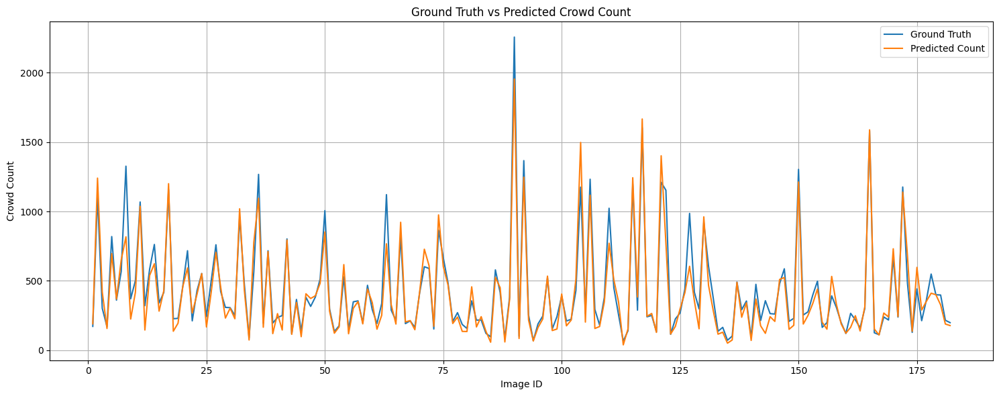

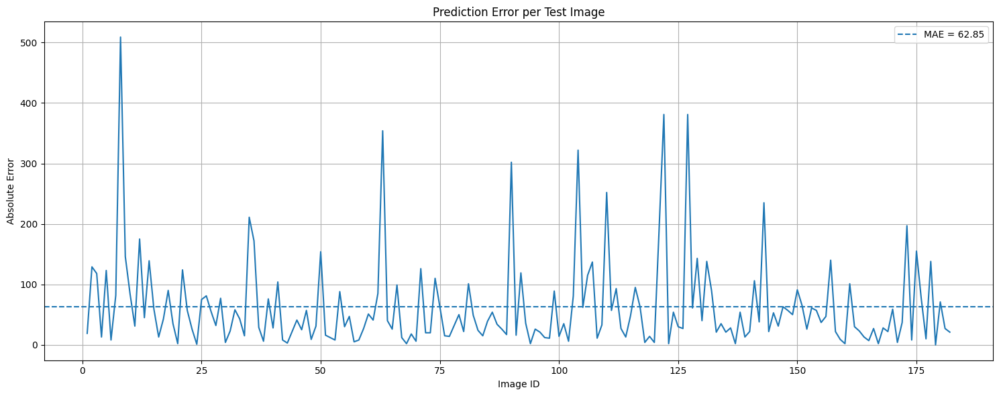

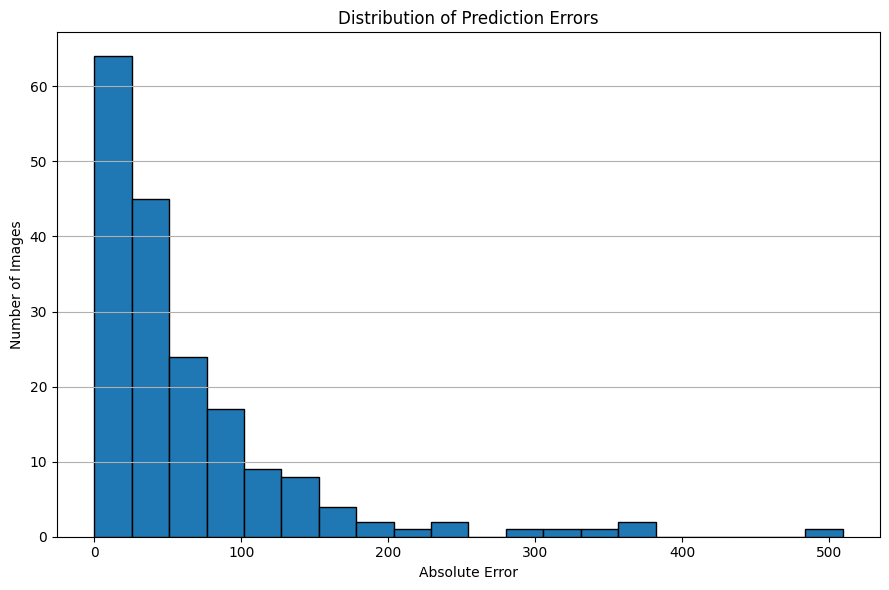

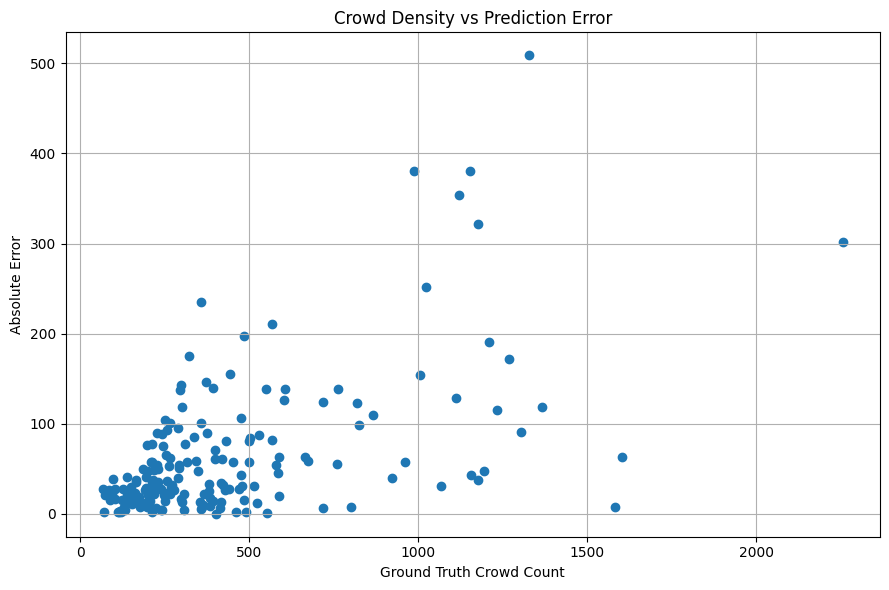


All graphs saved successfully!
Graph folder: /kaggle/working/p2p_graphs
CSV file: /kaggle/working/p2p_graphs/prediction_results.csv


In [31]:

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Folder containing the GT and prediction images
VIS_DIR = Path("/kaggle/working/p2p_full_visualizations")
GRAPH_DIR = Path("/kaggle/working/p2p_graphs")
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

# Extract GT and predicted counts from filenames
pattern = re.compile(r"^(\d+)_gt_(\d+)_pred_(\d+)_(gt|pred)\.jpg$")

records = {}

for file in VIS_DIR.glob("*.jpg"):
    match = pattern.match(file.name)

    if match:
        image_id = int(match.group(1))
        gt_count = int(match.group(2))
        pred_count = int(match.group(3))

        records[image_id] = {
            "Image_ID": image_id,
            "GT_Count": gt_count,
            "Pred_Count": pred_count
        }

df = pd.DataFrame(records.values()).sort_values("Image_ID").reset_index(drop=True)

if len(df) == 0:
    raise ValueError("No valid visualization filenames found. Check VIS_DIR.")

df["Absolute_Error"] = abs(df["GT_Count"] - df["Pred_Count"])
df["Squared_Error"] = (df["GT_Count"] - df["Pred_Count"]) ** 2

# Calculate metrics from extracted counts
mae = df["Absolute_Error"].mean()
rmse = np.sqrt(df["Squared_Error"].mean())

print("Total test images:", len(df))
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

display(df.head(10))

# -------------------------------------
# GRAPH 1: Ground Truth vs Prediction
# -------------------------------------
plt.figure(figsize=(15, 6))
plt.plot(df["Image_ID"], df["GT_Count"], label="Ground Truth")
plt.plot(df["Image_ID"], df["Pred_Count"], label="Predicted Count")
plt.xlabel("Image ID")
plt.ylabel("Crowd Count")
plt.title("Ground Truth vs Predicted Crowd Count")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(GRAPH_DIR / "01_GT_vs_Prediction.png", dpi=300)
plt.show()

# -------------------------------------
# GRAPH 2: Absolute Error per Image
# -------------------------------------
plt.figure(figsize=(15, 6))
plt.plot(df["Image_ID"], df["Absolute_Error"])
plt.axhline(mae, linestyle="--", label=f"MAE = {mae:.2f}")
plt.xlabel("Image ID")
plt.ylabel("Absolute Error")
plt.title("Prediction Error per Test Image")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(GRAPH_DIR / "02_Absolute_Error.png", dpi=300)
plt.show()

# -------------------------------------
# GRAPH 3: Error Distribution
# -------------------------------------
plt.figure(figsize=(9, 6))
plt.hist(df["Absolute_Error"], bins=20, edgecolor="black")
plt.xlabel("Absolute Error")
plt.ylabel("Number of Images")
plt.title("Distribution of Prediction Errors")
plt.grid(axis="y")
plt.tight_layout()
plt.savefig(GRAPH_DIR / "03_Error_Distribution.png", dpi=300)
plt.show()

# -------------------------------------
# GRAPH 4: GT Count vs Absolute Error
# -------------------------------------
plt.figure(figsize=(9, 6))
plt.scatter(df["GT_Count"], df["Absolute_Error"])
plt.xlabel("Ground Truth Crowd Count")
plt.ylabel("Absolute Error")
plt.title("Crowd Density vs Prediction Error")
plt.grid(True)
plt.tight_layout()
plt.savefig(GRAPH_DIR / "04_Density_vs_Error.png", dpi=300)
plt.show()

# -------------------------------------
# Export data and graph locations
# -------------------------------------
df.to_csv(GRAPH_DIR / "prediction_results.csv", index=False)

print("\nAll graphs saved successfully!")
print("Graph folder:", GRAPH_DIR)
print("CSV file:", GRAPH_DIR / "prediction_results.csv")


In [32]:

import pandas as pd
import numpy as np

csv_path = "/kaggle/working/p2p_graphs/prediction_results.csv"
df = pd.read_csv(csv_path)

df["Error"] = df["Pred_Count"] - df["GT_Count"]

print("========== TEST PERFORMANCE ==========")
print("Total Images:", len(df))
print("MAE:", round(df["Absolute_Error"].mean(), 4))
print("RMSE:", round(np.sqrt((df["Error"]**2).mean()), 4))

print("\n========== PREDICTION ANALYSIS ==========")
print("Underestimated images:", (df["Error"] < 0).sum())
print("Overestimated images:", (df["Error"] > 0).sum())
print("Exact predictions:", (df["Error"] == 0).sum())

print("\n========== CROWD DENSITY ANALYSIS ==========")

df["Density"] = pd.cut(
    df["GT_Count"],
    bins=[-1, 100, 300, 600, float("inf")],
    labels=["Low (0-100)", "Medium (101-300)",
            "High (301-600)", "Very High (600+)"]
)

result = df.groupby("Density", observed=False).agg(
    Images=("Image_ID", "count"),
    MAE=("Absolute_Error", "mean"),
    Average_GT=("GT_Count", "mean"),
    Average_Pred=("Pred_Count", "mean")
)

display(result.round(3))


========== TEST PERFORMANCE ==========
Total Images: 182
MAE: 62.8516
RMSE: 99.0

========== PREDICTION ANALYSIS ==========
Underestimated images: 118
Overestimated images: 63
Exact predictions: 1

========== CROWD DENSITY ANALYSIS ==========


,Images,MAE,Average_GT,Average_Pred
Density,,,,
Low (0-100),7,21.714,81.714,60.000
Medium (101-300),81,35.790,206.074,188.901
High (301-600),60,58.983,428.317,420.200
Very High (600+),34,142.618,1059.029,992.588


========== FINAL TEST METRICS ==========
Images: 182
MAE: 62.8516
RMSE: 99.0
Mean Bias: -23.5659
Correlation: 0.9624


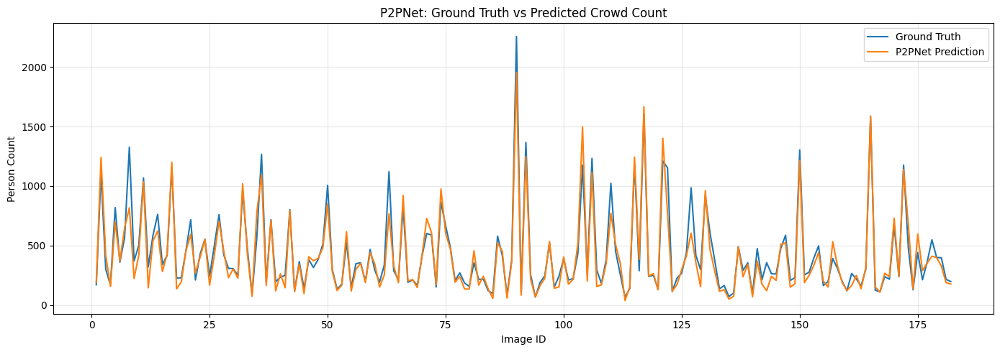

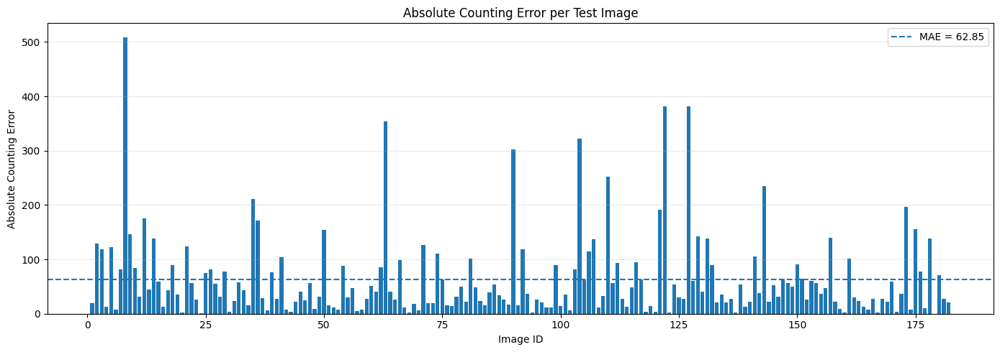

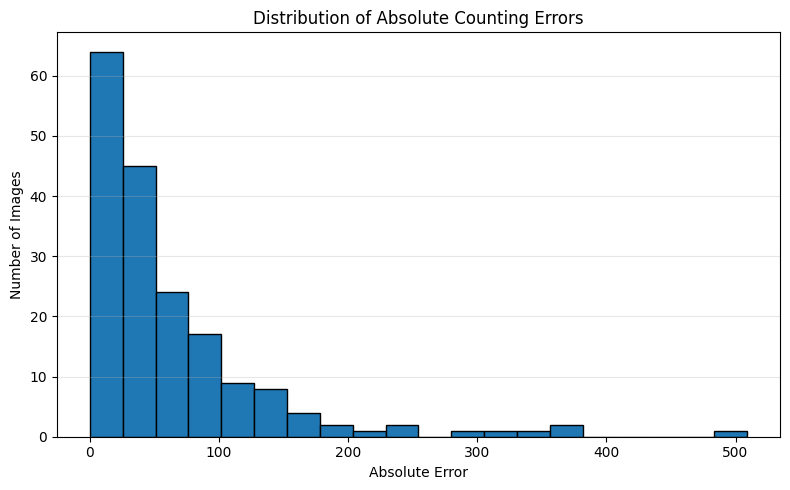

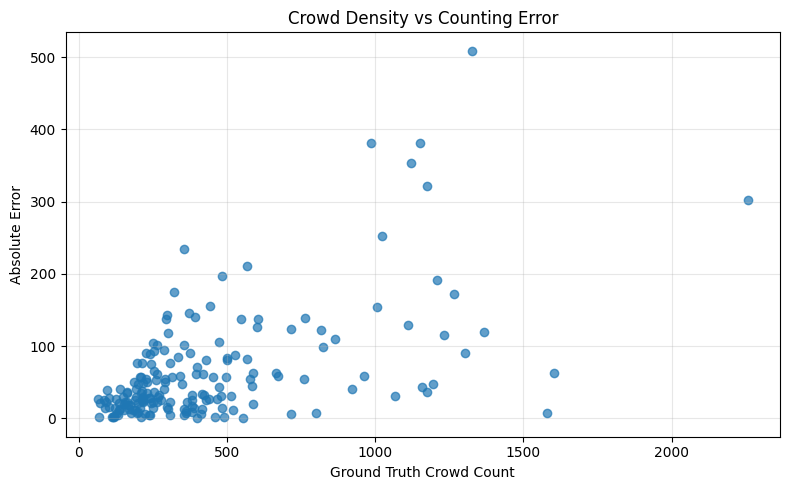

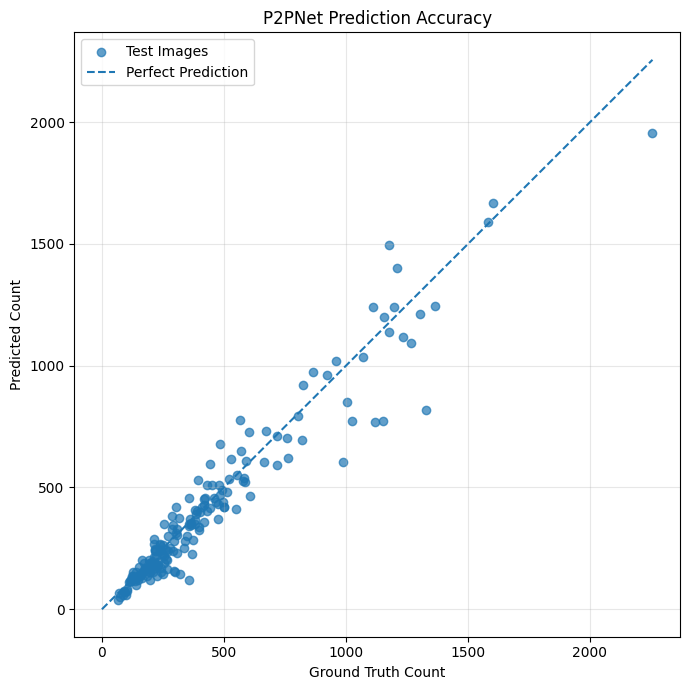

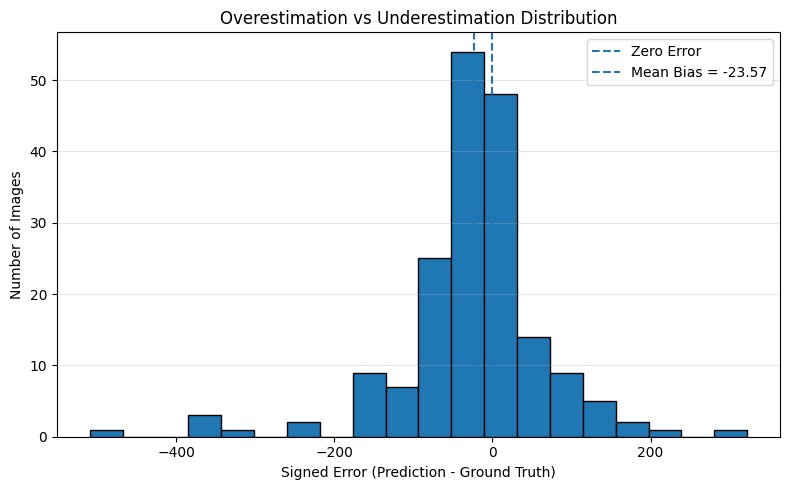


All 6 graphs saved in: /kaggle/working/p2p_graphs
Files:
01_GT_vs_Prediction.png
02_Absolute_Error.png
03_Error_Distribution.png
04_Density_vs_Error.png
05_GT_vs_Pred_Scatter.png
06_Signed_Error_Distribution.png


In [33]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load actual test predictions
CSV_PATH = "/kaggle/working/p2p_graphs/prediction_results.csv"
GRAPH_DIR = Path("/kaggle/working/p2p_graphs")
GRAPH_DIR.mkdir(exist_ok=True)

df = pd.read_csv(CSV_PATH)

gt = df["GT_Count"]
pred = df["Pred_Count"]
error = pred - gt
abs_error = abs(error)

# Metrics
mae = abs_error.mean()
rmse = np.sqrt((error ** 2).mean())

print("========== FINAL TEST METRICS ==========")
print("Images:", len(df))
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("Mean Bias:", round(error.mean(), 4))
print("Correlation:", round(gt.corr(pred), 4))

# 1. Ground Truth vs Prediction
plt.figure(figsize=(14, 5))
plt.plot(df["Image_ID"], gt, label="Ground Truth", linewidth=1.5)
plt.plot(df["Image_ID"], pred, label="P2PNet Prediction", linewidth=1.5)
plt.xlabel("Image ID")
plt.ylabel("Person Count")
plt.title("P2PNet: Ground Truth vs Predicted Crowd Count")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(GRAPH_DIR / "01_GT_vs_Prediction.png", dpi=300)
plt.show()

# 2. Absolute Error per Image
plt.figure(figsize=(14, 5))
plt.bar(df["Image_ID"], abs_error)
plt.axhline(mae, linestyle="--", label=f"MAE = {mae:.2f}")
plt.xlabel("Image ID")
plt.ylabel("Absolute Counting Error")
plt.title("Absolute Counting Error per Test Image")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(GRAPH_DIR / "02_Absolute_Error.png", dpi=300)
plt.show()

# 3. Error Distribution
plt.figure(figsize=(8, 5))
plt.hist(abs_error, bins=20, edgecolor="black")
plt.xlabel("Absolute Error")
plt.ylabel("Number of Images")
plt.title("Distribution of Absolute Counting Errors")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(GRAPH_DIR / "03_Error_Distribution.png", dpi=300)
plt.show()

# 4. Ground Truth Count vs Absolute Error
plt.figure(figsize=(8, 5))
plt.scatter(gt, abs_error, alpha=0.7)
plt.xlabel("Ground Truth Crowd Count")
plt.ylabel("Absolute Error")
plt.title("Crowd Density vs Counting Error")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(GRAPH_DIR / "04_Density_vs_Error.png", dpi=300)
plt.show()

# 5. Ground Truth vs Prediction Scatter
plt.figure(figsize=(7, 7))
plt.scatter(gt, pred, alpha=0.7, label="Test Images")

limit = max(gt.max(), pred.max())
plt.plot([0, limit], [0, limit], linestyle="--", label="Perfect Prediction")

plt.xlabel("Ground Truth Count")
plt.ylabel("Predicted Count")
plt.title("P2PNet Prediction Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(GRAPH_DIR / "05_GT_vs_Pred_Scatter.png", dpi=300)
plt.show()

# 6. Signed Error Distribution
plt.figure(figsize=(8, 5))
plt.hist(error, bins=20, edgecolor="black")
plt.axvline(0, linestyle="--", label="Zero Error")
plt.axvline(error.mean(), linestyle="--",
            label=f"Mean Bias = {error.mean():.2f}")
plt.xlabel("Signed Error (Prediction - Ground Truth)")
plt.ylabel("Number of Images")
plt.title("Overestimation vs Underestimation Distribution")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(GRAPH_DIR / "06_Signed_Error_Distribution.png", dpi=300)
plt.show()

print("\nAll 6 graphs saved in:", GRAPH_DIR)
print("Files:")
for file in sorted(GRAPH_DIR.glob("*.png")):
    print(file.name)


In [ ]:
%cd /kaggle/working/SafeCrowd-AI
!git checkout --orphan p2p_training
!git rm -rf .
!git config user.name "AdibaHusan"
!git config user.email "amritakushwah11112004@gmail.com"

In [ ]:
from kaggle_secrets import UserSecretsClient
token = UserSecretsClient().get_secret("GH_TOKEN").strip()   # strip() extra space/newline hata deta hai

!curl -s -H "Authorization: token {token}" https://api.github.com/user | grep '"login"'
!curl -s -H "Authorization: token {token}" https://api.github.com/repos/AdibaHusan/SafeCrowd-AI | grep -E '"full_name"|"push"'

In [ ]:
cp ~/Downloads/p2p_training.ipynb .
cp ~/Downloads/prepare_shha_for_p2pnet.py .